# Surya Forward Pass


## 0. Prerrequisites and imports

In [1]:
import timm, torch
from torch.utils.data import DataLoader
import sys
sys.path.append("../../Surya")
import yaml
import matplotlib.pyplot as plt

## 1. Test ViT

Let's download the tiny ViT model `vit_tiny_patch16_224.augreg_in21k_ft_in1k` for image classification to simulate how it should be done with a bigger model like Surya.

In [2]:
model = timm.create_model('vit_tiny_patch16_224.augreg_in21k_ft_in1k', pretrained=True)
model.eval()

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=192, out_features=576, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=192, out_features=192, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=192, out_features=768, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)


`timm`, trhough the method `forward_features`, exposes the recovered vectores after the 12 transformer blocks (attention + MLP) that describe in a vector manner each patch but including information about how they are related with each of the other patches.

In [3]:
x = torch.randn(1, 3, 224, 224)  # imagen dummy
with torch.no_grad():
    tokens = model.forward_features(x)

print(tokens.shape)  # (1, 197, 192) -- 196 parches de 16x16 + 1 token CLS

torch.Size([1, 197, 192])


## 2. Download checkpoints and validation data

Download Surya model with its checktpoints, the scalres and the configuration to work as expected. Also download the validation dataset.

In [4]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="nasa-ibm-ai4science/Surya-1.0",
    local_dir="data/Surya-1.0",
    allow_patterns=["config.yaml", "scalers.yaml", "surya.366m.v1.pt"],
)
snapshot_download(
    repo_id="nasa-ibm-ai4science/Surya-1.0_validation_data",
    repo_type="dataset",
    local_dir="data/Surya-1.0_validation_data",
    allow_patterns="20140107_1[5-9]??.nc",
)


Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

'/scratchsan/observatorio/juagudeloo/Doctorado/vision-language-model-surya/notebook/data/Surya-1.0_validation_data'

## 3. Building the model

In [5]:
from surya.models.helio_spectformer import HelioSpectFormer

/homes/observatorio/juagudeloo/.conda/envs/pytorch_jupyter/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Let's instantiate an object with the Surya model architecture but with the weights randomly initialized.

In [6]:
# model configuration from the `config.yaml` file
with open("data/Surya-1.0/config.yaml") as fp:
    config = yaml.safe_load(fp)

In [7]:
model = HelioSpectFormer(
    img_size=config["model"]["img_size"],
    patch_size=config["model"]["patch_size"],
    in_chans=len(config["data"]["sdo_channels"]),
    embed_dim=config["model"]["embed_dim"],
    time_embedding={
        "type": "linear",
        "time_dim": len(config["data"]["time_delta_input_minutes"]),
    },
    depth=config["model"]["depth"],
    n_spectral_blocks=config["model"]["n_spectral_blocks"],
    num_heads=config["model"]["num_heads"],
    mlp_ratio=config["model"]["mlp_ratio"],
    drop_rate=config["model"]["drop_rate"],
    window_size=config["model"]["window_size"],
    dp_rank=config["model"]["dp_rank"],
    learned_flow=config["model"]["learned_flow"],
    rpe=config["model"]["rpe"],
    ensemble=config["model"]["ensemble"],
    finetune=config["model"]["finetune"],
)

print(type(model.embedding).__name__, type(model.backbone).__name__, type(model.unembed).__name__)
print("spectral:", len(model.backbone.blocks_spectral_gating), "attention:", len(model.backbone.blocks_attention))
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parametros")


LinearEmbedding SpectFormer LinearDecoder
spectral: 2 attention: 8
366.2 M parametros


## 4. Upload actual dataset

In [8]:
from surya.datasets.helio import HelioNetCDFDataset
from surya.utils.data import build_scalers, custom_collate_fn

Let's charge the configuration and the scaler metrics from the `config.yaml` and `scalers.yaml` files.

In [9]:
with open("data/Surya-1.0/config.yaml") as fp:
    config = yaml.safe_load(fp)

scalers_info = yaml.safe_load(open("data/Surya-1.0/scalers.yaml"))
scalers = build_scalers(info=scalers_info)

For uploading the dataset we need the uploader class `HelioNetCDFDataset` that parses the netCDF.

In [10]:
dataset = HelioNetCDFDataset(
    index_path="../../Surya/tests/test_surya_index.csv",  # el índice real del repo de Surya
    time_delta_input_minutes=config["data"]["time_delta_input_minutes"],
    time_delta_target_minutes=config["data"]["time_delta_target_minutes"],
    n_input_timestamps=len(config["data"]["time_delta_input_minutes"]),
    rollout_steps=1,
    channels=config["data"]["sdo_channels"],
    drop_hmi_probability=0.0,
    num_mask_aia_channels=0,
    use_latitude_in_learned_flow=config["data"]["use_latitude_in_learned_flow"],
    scalers=scalers,
    phase="valid",
    pooling=config["data"]["pooling"],
    random_vert_flip=False,
)
print(f"{len(dataset)} sample(s) en el dataset")

8 sample(s) en el dataset


Let's convert it to a python dataloader.

In [11]:
dataloader = DataLoader(
    dataset, shuffle=False, batch_size=1, num_workers=0,
    pin_memory=False, drop_last=False, collate_fn=custom_collate_fn,
)

Let's see one of the items inside.

In [12]:
batch_data, batch_metadata = next(iter(dataloader))
print("ts:", batch_data["ts"].shape, batch_data["ts"].dtype)
print("time_delta_input:", batch_data["time_delta_input"].shape, batch_data["time_delta_input"])

ts: torch.Size([1, 13, 2, 4096, 4096]) torch.float32
time_delta_input: torch.Size([1, 2]) tensor([[1., 0.]])


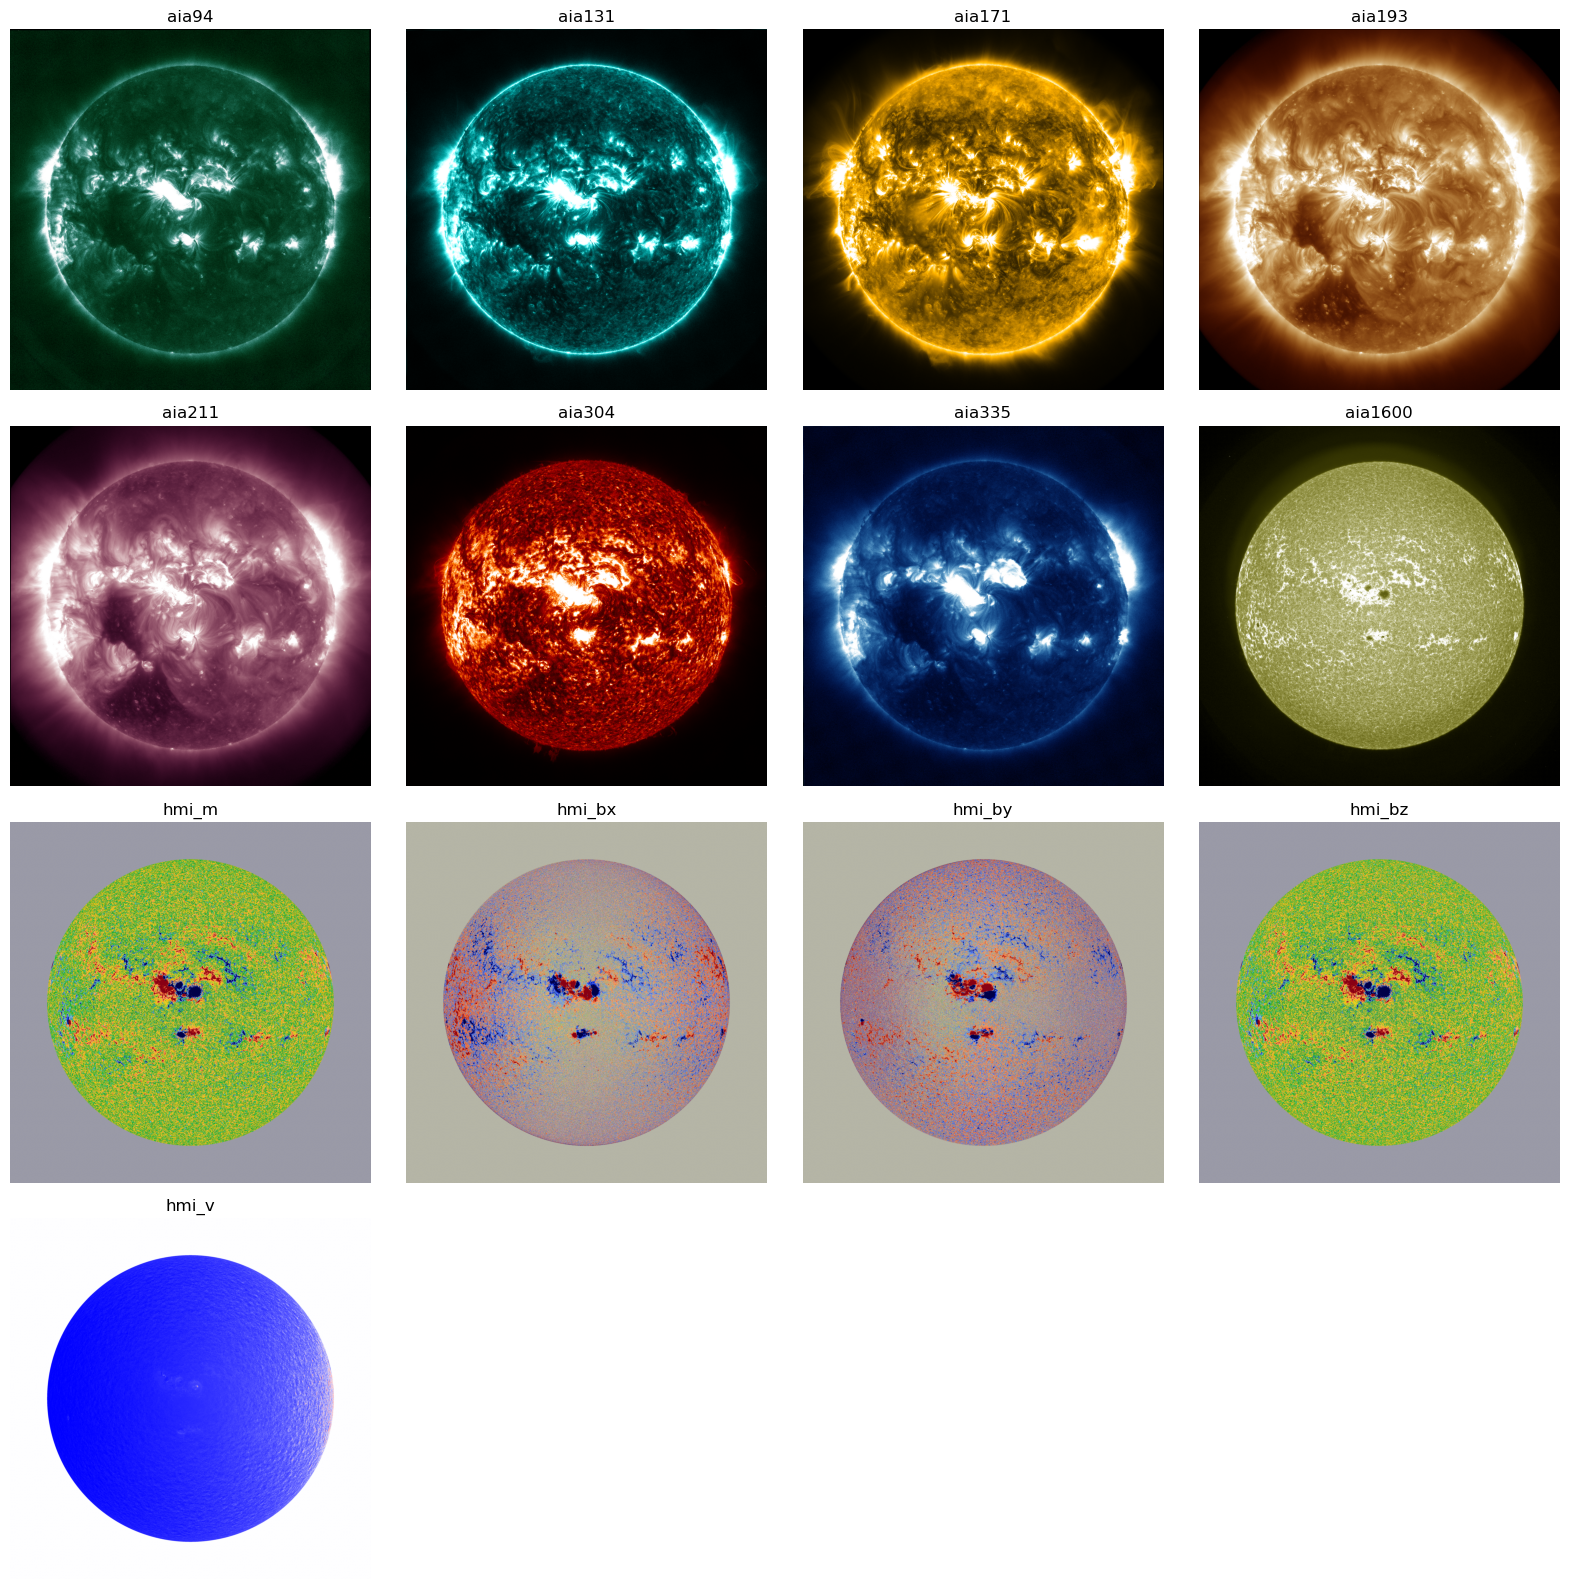

In [13]:
import numpy as np
import sunpy.visualization.colormaps as sunpy_cm

channel_cmaps = {
    "aia94": sunpy_cm.cmlist["sdoaia94"], "aia131": sunpy_cm.cmlist["sdoaia131"],
    "aia171": sunpy_cm.cmlist["sdoaia171"], "aia193": sunpy_cm.cmlist["sdoaia193"],
    "aia211": sunpy_cm.cmlist["sdoaia211"], "aia304": sunpy_cm.cmlist["sdoaia304"],
    "aia335": sunpy_cm.cmlist["sdoaia335"], "aia1600": sunpy_cm.cmlist["sdoaia1600"],
    "hmi_m": sunpy_cm.cmlist["hmimag"], "hmi_bx": sunpy_cm.cmlist["hmimag"],
    "hmi_by": sunpy_cm.cmlist["hmimag"], "hmi_bz": sunpy_cm.cmlist["hmimag"],
    "hmi_v": plt.get_cmap("bwr"),
}

channels = config["data"]["sdo_channels"]
fig, ax = plt.subplots(4, 4, figsize=(16, 16))
ax = ax.flatten()
for i, channel in enumerate(channels):
    arr = batch_data["ts"][0, i, 0].numpy()
    fill_value = arr[0, 0]  # el fondo fuera del disco es un relleno constante
    on_disk = arr[arr != fill_value]
    if channel.startswith("hmi"):
        vabs = np.percentile(np.abs(on_disk), 98)
        vmin, vmax = -vabs, vabs  # centrado en 0: campo/velocidad con signo
    else:
        vmin, vmax = np.percentile(on_disk, [2, 98])
    ax[i].imshow(arr, cmap=channel_cmaps[channel], vmin=vmin, vmax=vmax)
    ax[i].set_title(channel)
    ax[i].axis("off")
for j in range(len(channels), len(ax)):
    ax[j].axis("off")
plt.tight_layout()
plt.show()


## 5. Weights and Embedding Encoder

Let's convert our instantiated model into Surya by uploading the corresponding weights.

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.reset_peak_memory_stats()

model.to(device)
model.eval()
print(f"Modelo en {device}, {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parametros")
print(f"VRAM tras mover el modelo a GPU: {torch.cuda.memory_allocated() / 1e9:.3f} GB")

Modelo en cuda, 366.2 M parametros
VRAM tras mover el modelo a GPU: 1.821 GB


In [15]:
weights = torch.load("data/Surya-1.0/surya.366m.v1.pt", map_location=device)
model.load_state_dict(weights, strict=True)
model.eval()

HelioSpectFormer(
  (embedding): LinearEmbedding(
    (patch_embed): PatchEmbed3D(
      (proj): Conv2d(26, 1280, kernel_size=(16, 16), stride=(16, 16))
    )
    (pos_drop): Dropout(p=0.0, inplace=False)
  )
  (unembed): LinearDecoder(
    (unembed): Sequential(
      (0): Conv2d(1280, 3328, kernel_size=(1, 1), stride=(1, 1))
      (1): PixelShuffle(upscale_factor=16)
    )
  )
  (backbone): SpectFormer(
    (blocks_spectral_gating): ModuleList(
      (0-1): 2 x BlockSpectralGating(
        (norm1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (filter): SpectralGatingNetwork()
        (drop_path): Identity()
        (norm2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=1280, out_features=5120, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=5120, out_features=1280, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (blocks_att

With the weights uploaded, let's make a pass on the sample input we extracted earlier.

In [16]:
with torch.no_grad():
    tokens = model.embedding(batch_data["ts"].to(device), batch_data["time_delta_input"].to(device))
    tokens = model.backbone(tokens)

torch.cuda.synchronize()
print(f"tokens.shape: {tuple(tokens.shape)}")
print(f"VRAM tras el forward pass: {torch.cuda.memory_allocated() / 1e9:.3f} GB")
print(f"VRAM pico durante todo el proceso: {torch.cuda.max_memory_allocated() / 1e9:.3f} GB")


tokens.shape: (1, 65536, 1280)
VRAM tras el forward pass: 3.987 GB
VRAM pico durante todo el proceso: 8.936 GB


## 6. Output visualization

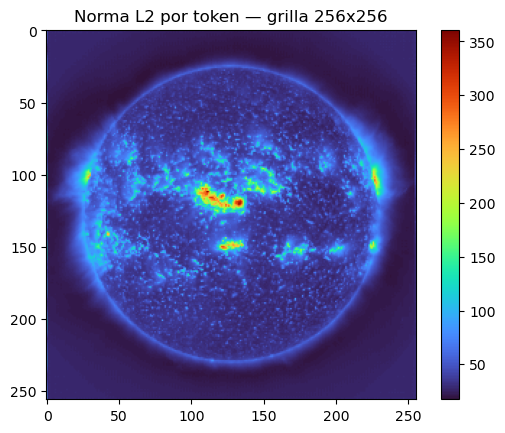

In [ ]:
norms = tokens[0].norm(dim=-1).reshape(256, 256).cpu()
plt.imshow(norms, cmap="turbo")
plt.title("Norma L2 por token — grilla 256x256")
plt.colorbar()
plt.savefig("forward_pass_embedding_norm.png", dpi=100, bbox_inches="tight")
